# C03b — What kinds of X occur?
Canonical detector: **full project-defined FZ186 (186 features)**. FZ182 remains a historical ablation, not an interchangeable baseline. Feature interventions will be evaluated primarily by paired changes in signed feature contributions using the frozen model and fixed human references; AUC is secondary.

This notebook is a descriptive audit, with no edits or retraining. It reports X token types, document prevalence, genre breakdowns and contexts. Type labels are review aids, not claims about communicative function. In particular `>` may be quoting, navigation, comparison or list formatting. Hyphens are inspected across **all POS labels**, since a formatting difference can cross feature categories.

Run after C03a. Set its run directory explicitly if several exist. All figures save as PDF and PNG to `reproduction/figures/`. Document-level X contributions cannot be attributed to individual token types by this audit.


In [1]:
from pathlib import Path
import json,hashlib,re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd() if (Path.cwd()/'results').exists() else Path.cwd().parent
AUDIT_DIR=None
if AUDIT_DIR is None:
    choices=sorted(p.parent for p in (ROOT/'results/causal/C03a_POS_X_audit').glob('*/X_token_contexts.csv'))
    if len(choices)!=1:raise RuntimeError(f'Set AUDIT_DIR to one run: {choices}')
    AUDIT_DIR=choices[0]
AUDIT_DIR=Path(AUDIT_DIR)
audit_contract=json.loads((AUDIT_DIR/'contract.json').read_text())
parents=[p.parent for p in (ROOT/'results/causal/C03_fz186_raid_fixed54').glob('*/contract.json') if hashlib.sha256(p.read_bytes()).hexdigest()==audit_contract['parent_contract']]
assert len(parents)==1
PARENT=parents[0];parent_contract=json.loads((PARENT/'contract.json').read_text())
for rel,h in parent_contract['inputs'].items():assert hashlib.sha256((ROOT/rel).read_bytes()).hexdigest()==h, f'Changed input: {rel}'
docs=pd.read_csv(AUDIT_DIR/'X_document_audit.csv',keep_default_na=False)
tokens=pd.read_csv(AUDIT_DIR/'X_token_contexts.csv',keep_default_na=False)
nb=ROOT/'experiments/C03b_X_types.ipynb'
contract=dict(canonical_model='FZ186: full 186 columns',parent=audit_contract,
 code=hashlib.sha256(json.dumps([c['source'] for c in json.loads(nb.read_text())['cells'] if c['cell_type']=='code']).encode()).hexdigest())
run=hashlib.sha256(json.dumps(contract,sort_keys=True).encode()).hexdigest()[:12]
OUT=ROOT/'results/causal/C03b_X_types'/run;OUT.mkdir(parents=True,exist_ok=True)
FIG=ROOT/'figures';FIG.mkdir(exist_ok=True)
(OUT/'contract.json').write_text(json.dumps(contract,indent=2))
GROUPS=['Fixed AI','Original AI source','Human test']
mix=docs.loc[docs.group.eq('Fixed AI'),'domain'].value_counts(normalize=True)
def savefig(fig,stem):
    fig.tight_layout()
    for folder in (OUT,FIG):
        for ext in ('pdf','png'):fig.savefig(folder/f'C03b_{stem}.{ext}',bbox_inches='tight',dpi=300)
    plt.show()


,group,X_type,token_count,documents_with_type,weighted_prevalence,weighted_per_1000_tokens
3,Fixed AI,List-item tag (LS),52,7,0.129630,3.472399
0,Fixed AI,Angle markers,13,2,0.037037,0.826125
1,Fixed AI,Brackets,2,1,0.018519,0.209249
7,Fixed AI,edit token (inspect context),2,1,0.018519,0.209249
6,Fixed AI,URL-like,3,1,0.018519,0.131337
2,Fixed AI,Foreign-word tag (FW),2,1,0.018519,0.098503
4,Fixed AI,Other ADD-tagged,1,1,0.018519,0.061728
5,Fixed AI,Other lexical/fragments,0,0,0.000000,0.000000
10,Human test,Foreign-word tag (FW),26,9,0.072670,0.886853
11,Human test,List-item tag (LS),22,6,0.048079,0.678993


,group,X_type,token,fine_tag,count,documents
4,Fixed AI,List-item tag (LS),.,LS,16,4
1,Fixed AI,Angle markers,>,XX,12,2
5,Fixed AI,List-item tag (LS),2,LS,7,7
6,Fixed AI,List-item tag (LS),3,LS,7,7
7,Fixed AI,List-item tag (LS),4,LS,7,7
...,...,...,...,...,...,...
58,Original AI source,List-item tag (LS),9,LS,1,1
59,Original AI source,Other ADD-tagged,_,ADD,1,1
60,Original AI source,Other ADD-tagged,about/,ADD,1,1
61,Original AI source,Other ADD-tagged,mid-50s,ADD,1,1


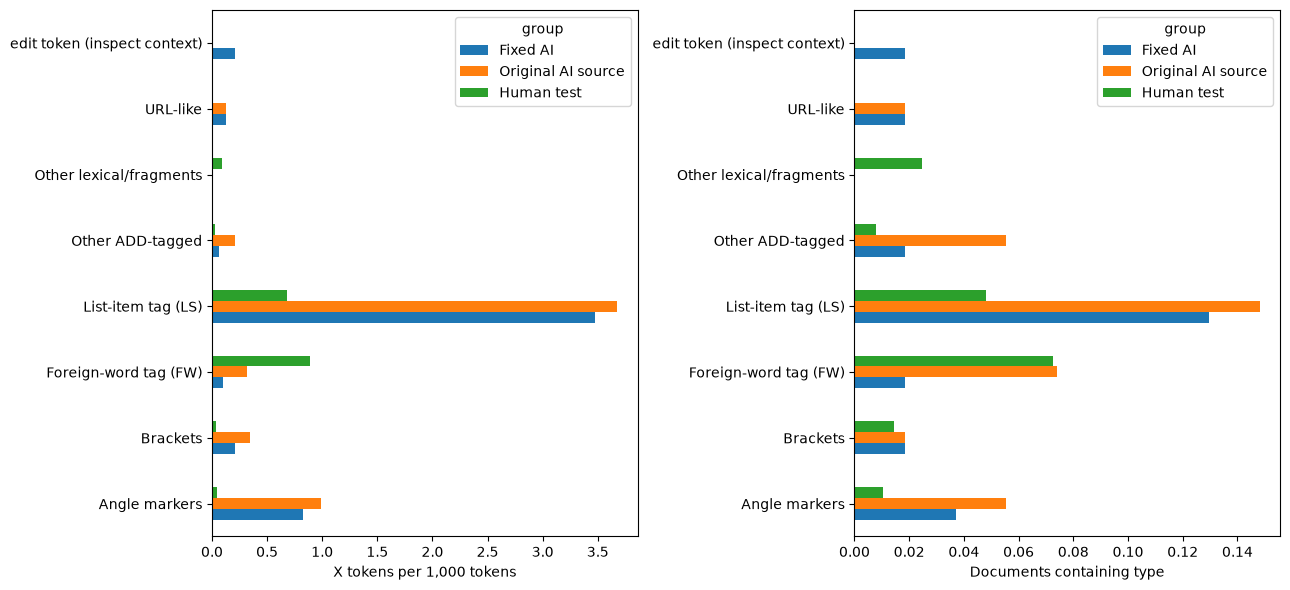


TYPE: Angle markers
Fixed AI
  gate_0004 [recipes] '>' / XX: > 8-1/2 cups water, divided > 4 small carrots, chopped > 3 stalks celery, diced > 4 cloves garlic, minced > 2 leeks (white part only) cut into pieces > 6 (6 oz.) packages fresh baby spinach leaves > One 4 lb turkey, cooked and diced or shredded > 8 tomatos (or equivalent amount frozen tomatoes) > 2 tsp dried rosemary > 2 bay leaves > Salt & Pepper to taste > Corn meal noodles combine in food processor mix 1 cup cornmeal, 1 teaspoon salt and 4 cups hot tap water; pulse mixture until dough comes together then set aside for 5 minutes.
  gate_0047 [books] '>' / XX: Summary Next >  Most recently added  Author biography
Original AI source
  gate_0004 [recipes] '>' / XX: > 8-1/2 cups water, divided > 4 small carrots, chopped > 3 stalks celery, diced > 4 cloves garlic, minced > 2 leeks (white part only), cut into pieces > 6 (6 oz.) packages fresh baby spinach leaves > One 4 lb turkey, cooked and diced or shredded > 8 tomatos (or equ

In [2]:
def token_type(r):
    t=r.token
    if r.fine_tag=='LS':return 'List-item tag (LS)'
    if t in ('>','<','>>','<<'):return 'Angle markers'
    if re.search(r'(?:https?://|www\.|\.(?:com|org|net)(?:/|$))',t,re.I):return 'URL-like'
    if t.lower()=='edit':return 'edit token (inspect context)'
    if t in ('[',']','{','}'):return 'Brackets'
    if r.fine_tag=='FW':return 'Foreign-word tag (FW)'
    if r.fine_tag=='ADD':return 'Other ADD-tagged'
    if re.fullmatch(r'[^\w\s]+',t):return 'Other symbols'
    return 'Other lexical/fragments'
tokens['X_type']=tokens.apply(token_type,axis=1)
tokens.to_csv(OUT/'X_typed_contexts.csv',index=False)
# Include zero-X documents in every denominator.
types=sorted(tokens.X_type.unique());records=[]
for group in GROUPS:
    d=docs.loc[docs.group.eq(group)]
    for genre in sorted(mix.index):
        dd=d.loc[d.domain.eq(genre)]
        for typ in types:
            tt=tokens.loc[tokens.group.eq(group)&tokens.domain.eq(genre)&tokens.X_type.eq(typ)]
            count=tt.groupby('case_id').size()
            per=dd.case_id.map(count).fillna(0).to_numpy()
            records.append(dict(group=group,domain=genre,X_type=typ,documents=len(dd),token_count=len(tt),documents_with_type=int((per>0).sum()),document_prevalence=(per>0).mean(),mean_per_1000_tokens=np.mean(1000*per/dd.n_tokens.to_numpy())))
bygenre=pd.DataFrame(records);bygenre.to_csv(OUT/'X_types_by_genre.csv',index=False)
weighted=[]
for (group,typ),s in bygenre.groupby(['group','X_type']):
    w=s.domain.map(mix).to_numpy()
    weighted.append(dict(group=group,X_type=typ,token_count=s.token_count.sum(),documents_with_type=s.documents_with_type.sum(),weighted_prevalence=np.sum(w*s.document_prevalence),weighted_per_1000_tokens=np.sum(w*s.mean_per_1000_tokens)))
summary=pd.DataFrame(weighted).sort_values(['group','weighted_per_1000_tokens'],ascending=[True,False])
summary.to_csv(OUT/'X_type_summary.csv',index=False);display(summary)
lex=tokens.groupby(['group','X_type','token','fine_tag']).agg(count=('case_id','size'),documents=('case_id','nunique')).reset_index().sort_values(['group','count'],ascending=[True,False])
lex.to_csv(OUT/'X_token_frequencies.csv',index=False);display(lex)
fig,axs=plt.subplots(1,2,figsize=(13,6))
for ax,col,title in zip(axs,['weighted_per_1000_tokens','weighted_prevalence'],['X tokens per 1,000 tokens','Documents containing type']):
    summary.pivot(index='X_type',columns='group',values=col)[GROUPS].plot.barh(ax=ax)
    ax.set(xlabel=title,ylabel='')
savefig(fig,'X_type_comparison')
# Print representative contexts by type and group; full contexts retained in CSV.
for typ in types:
    print('\nTYPE:',typ)
    for group in GROUPS:
        print(group)
        for r in tokens.loc[tokens.X_type.eq(typ)&tokens.group.eq(group)].drop_duplicates(['case_id','sentence']).head(8).itertuples():
            print(f'  {r.case_id} [{r.domain}] {r.token!r} / {r.fine_tag}: {r.sentence}')


In [3]:
# Inspect marker roles in the original stored layout, independently of POS.
# These are candidates for manual review, NOT automatic list/quote assignments.
base=ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
corpus=pd.read_parquet(base/'paired_corpus.parquet').set_index('source_id')
data=pd.read_csv(ROOT/'results/causal/C02w_adaptive_camouflage_v1/final_texts_54.csv',keep_default_na=False).set_index('case_id')
marker_rows=[];doc_marker=[]
for r in docs.itertuples():
    text=str(data.loc[r.case_id,'text']) if r.group=='Fixed AI' else str(corpus.loc[r.source_id,'text'])
    lines=text.splitlines() or [text]
    count={k:0 for k in ['greater_than','hyphen','en_dash','em_dash','bullet']}
    for li,line in enumerate(lines):
        for m in re.finditer(r'[>\-–—•]',line):
            typ={'>':'greater_than','-':'hyphen','–':'en_dash','—':'em_dash','•':'bullet'}[m.group()];count[typ]+=1
            before=line[:m.start()];after=line[m.end():]
            position='line-leading candidate' if not before.strip() else ('within-word candidate' if before[-1:].isalnum() and after[:1].isalnum() else 'inline candidate')
            marker_rows.append(dict(group=r.group,case_id=r.case_id,domain=r.domain,marker=m.group(),marker_type=typ,position=position,line_number=li+1,line=line,previous_line=lines[li-1] if li else '',next_line=lines[li+1] if li+1<len(lines) else '',reviewed_role=''))
    doc_marker.append(dict(group=r.group,case_id=r.case_id,domain=r.domain,n_tokens=r.n_tokens,n_lines=len(lines),**count))
markers=pd.DataFrame(marker_rows);dm=pd.DataFrame(doc_marker)
markers.to_csv(OUT/'marker_contexts_for_review.csv',index=False);dm.to_csv(OUT/'marker_document_counts.csv',index=False)
mr=[]
for (group,genre),s in dm.groupby(['group','domain']):
    for typ in count:
        mr.append(dict(group=group,domain=genre,marker_type=typ,documents=len(s),document_prevalence=s[typ].gt(0).mean(),mean_per_1000_tokens=(1000*s[typ]/s.n_tokens).mean()))
ms=pd.DataFrame(mr);ms.to_csv(OUT/'marker_rates_by_genre.csv',index=False)
display(ms.loc[ms.domain.eq('recipes')])
for group in GROUPS:
    print('\nRECIPE MARKER CONTEXTS:',group)
    display(markers.loc[markers.group.eq(group)&markers.domain.eq('recipes')].head(40))
print('Review roles such as list marker, quotation, navigation, comparison, compound-word hyphen, or uncertain.')
print('Line-leading evidence may be lost when stored text has already flattened newlines; inspect full sentence and surrounding content.')


,group,domain,marker_type,documents,document_prevalence,mean_per_1000_tokens
15,Fixed AI,recipes,greater_than,9,0.111111,4.329004
16,Fixed AI,recipes,hyphen,9,1.000000,8.414400
17,Fixed AI,recipes,en_dash,9,0.000000,0.000000
18,Fixed AI,recipes,em_dash,9,0.000000,0.000000
19,Fixed AI,recipes,bullet,9,0.000000,0.000000
50,Human test,recipes,greater_than,21,0.000000,0.000000
51,Human test,recipes,hyphen,21,0.952381,9.478209
52,Human test,recipes,en_dash,21,0.000000,0.000000
53,Human test,recipes,em_dash,21,0.000000,0.000000
54,Human test,recipes,bullet,21,0.000000,0.000000



RECIPE MARKER CONTEXTS: Fixed AI


,group,case_id,domain,marker,marker_type,position,line_number,line,previous_line,next_line,reviewed_role
8,Fixed AI,gate_0004,recipes,>,greater_than,line-leading candidate,1,"> 8-1/2 cups water, divided > 4 small carrots,...",,,
9,Fixed AI,gate_0004,recipes,-,hyphen,within-word candidate,1,"> 8-1/2 cups water, divided > 4 small carrots,...",,,
10,Fixed AI,gate_0004,recipes,>,greater_than,inline candidate,1,"> 8-1/2 cups water, divided > 4 small carrots,...",,,
11,Fixed AI,gate_0004,recipes,>,greater_than,inline candidate,1,"> 8-1/2 cups water, divided > 4 small carrots,...",,,
12,Fixed AI,gate_0004,recipes,>,greater_than,inline candidate,1,"> 8-1/2 cups water, divided > 4 small carrots,...",,,
13,Fixed AI,gate_0004,recipes,>,greater_than,inline candidate,1,"> 8-1/2 cups water, divided > 4 small carrots,...",,,
14,Fixed AI,gate_0004,recipes,>,greater_than,inline candidate,1,"> 8-1/2 cups water, divided > 4 small carrots,...",,,
15,Fixed AI,gate_0004,recipes,>,greater_than,inline candidate,1,"> 8-1/2 cups water, divided > 4 small carrots,...",,,
16,Fixed AI,gate_0004,recipes,>,greater_than,inline candidate,1,"> 8-1/2 cups water, divided > 4 small carrots,...",,,
17,Fixed AI,gate_0004,recipes,>,greater_than,inline candidate,1,"> 8-1/2 cups water, divided > 4 small carrots,...",,,



RECIPE MARKER CONTEXTS: Original AI source


,group,case_id,domain,marker,marker_type,position,line_number,line,previous_line,next_line,reviewed_role
124,Original AI source,gate_0004,recipes,>,greater_than,line-leading candidate,1,"> 8-1/2 cups water, divided",,"> 4 small carrots, chopped",
125,Original AI source,gate_0004,recipes,-,hyphen,within-word candidate,1,"> 8-1/2 cups water, divided",,"> 4 small carrots, chopped",
126,Original AI source,gate_0004,recipes,>,greater_than,line-leading candidate,2,"> 4 small carrots, chopped","> 8-1/2 cups water, divided","> 3 stalks celery, diced",
127,Original AI source,gate_0004,recipes,>,greater_than,line-leading candidate,3,"> 3 stalks celery, diced","> 4 small carrots, chopped","> 4 cloves garlic, minced",
128,Original AI source,gate_0004,recipes,>,greater_than,line-leading candidate,4,"> 4 cloves garlic, minced","> 3 stalks celery, diced","> 2 leeks (white part only), cut into pieces",
129,Original AI source,gate_0004,recipes,>,greater_than,line-leading candidate,5,"> 2 leeks (white part only), cut into pieces","> 4 cloves garlic, minced",> 6 (6 oz.) packages fresh baby spinach leaves,
130,Original AI source,gate_0004,recipes,>,greater_than,line-leading candidate,6,> 6 (6 oz.) packages fresh baby spinach leaves,"> 2 leeks (white part only), cut into pieces","> One 4 lb turkey, cooked and diced or shredded",
131,Original AI source,gate_0004,recipes,>,greater_than,line-leading candidate,7,"> One 4 lb turkey, cooked and diced or shredded",> 6 (6 oz.) packages fresh baby spinach leaves,> 8 tomatos (or equivalent amount frozen tomat...,
132,Original AI source,gate_0004,recipes,>,greater_than,line-leading candidate,8,> 8 tomatos (or equivalent amount frozen tomat...,"> One 4 lb turkey, cooked and diced or shredded",> 2 tsp dried rosemary,
133,Original AI source,gate_0004,recipes,>,greater_than,line-leading candidate,9,> 2 tsp dried rosemary,> 8 tomatos (or equivalent amount frozen tomat...,> 2 bay leaves,



RECIPE MARKER CONTEXTS: Human test


,group,case_id,domain,marker,marker_type,position,line_number,line,previous_line,next_line,reviewed_role
433,Human test,human__raid:3e7fb3a2-3d32-43b1-ba60-c4689d38caee,recipes,-,hyphen,within-word candidate,10,"5 cups all-purpose flour, sifted",12 teaspoon mace,13 cup currants,
434,Human test,human__raid:3f88fbdd-9dde-4766-a8db-05b0f2e0957e,recipes,-,hyphen,within-word candidate,5,1/2 lb. all-purpose flour,1/4 lb. sugar,Seedless raspberrry preserves,
435,Human test,human__raid:3f88fbdd-9dde-4766-a8db-05b0f2e0957e,recipes,-,hyphen,within-word candidate,12,"If you cannot buy nuts already ground, then gr...",1 tbsp. butter,,
436,Human test,human__raid:3f88fbdd-9dde-4766-a8db-05b0f2e0957e,recipes,-,hyphen,within-word candidate,12,"If you cannot buy nuts already ground, then gr...",1 tbsp. butter,,
437,Human test,human__raid:3f88fbdd-9dde-4766-a8db-05b0f2e0957e,recipes,-,hyphen,within-word candidate,12,"If you cannot buy nuts already ground, then gr...",1 tbsp. butter,,
450,Human test,human__raid:5e96071b-cd3e-4461-9948-96d041e63767,recipes,-,hyphen,within-word candidate,1,1 12-ounce package frozen unsweetened raspberr...,,"12 ounces cream cheese, room temperature",
451,Human test,human__raid:5e96071b-cd3e-4461-9948-96d041e63767,recipes,-,hyphen,within-word candidate,7,40 (about) Champagne biscuits (crisp ladyfinge...,1/2 cup fresh lemon juice,Fresh raspberries,
452,Human test,human__raid:5e96071b-cd3e-4461-9948-96d041e63767,recipes,-,hyphen,within-word candidate,7,40 (about) Champagne biscuits (crisp ladyfinge...,1/2 cup fresh lemon juice,Fresh raspberries,
453,Human test,human__raid:5e96071b-cd3e-4461-9948-96d041e63767,recipes,-,hyphen,within-word candidate,10,Puree thawed raspberries in processor until sm...,Fresh mint sprigs (optional),,
454,Human test,human__raid:5e96071b-cd3e-4461-9948-96d041e63767,recipes,-,hyphen,within-word candidate,10,Puree thawed raspberries in processor until sm...,Fresh mint sprigs (optional),,


Review roles such as list marker, quotation, navigation, comparison, compound-word hyphen, or uncertain.
Line-leading evidence may be lost when stored text has already flattened newlines; inspect full sentence and surrounding content.


In [4]:
# Descriptive association with document-level X contributions, not token attribution.
gaps=pd.read_csv(PARENT/'FZ186_case_contribution_gaps.csv').set_index('case_id')
xcols=['pos_X_token_share','pos_X_sentence_mean','pos_X_sentence_std','pos_X_sentence_max']
fixed=docs.loc[docs.group.eq('Fixed AI')].copy()
fixed['X_block_gap']=gaps.loc[fixed.case_id,xcols].sum(axis=1).to_numpy()
for typ in types:
    counts=tokens.loc[tokens.group.eq('Fixed AI')&tokens.X_type.eq(typ)].groupby('case_id').size()
    fixed[typ]=fixed.case_id.map(counts).fillna(0).astype(int)
fixed.to_csv(OUT/'X_types_and_document_contributions.csv',index=False)
display(fixed.sort_values('X_block_gap',ascending=False))
print('Saved audit:',OUT)
print('Next intervention endpoint: paired signed contribution drop for each targeted feature, with fixed human references; also check other features for displaced signal.')


,group,case_id,source_id,domain,n_tokens,n_X,pos_X_token_share,pos_X_sentence_mean,pos_X_sentence_std,pos_X_sentence_max,X_block_gap,Angle markers,Brackets,Foreign-word tag (FW),List-item tag (LS),Other ADD-tagged,Other lexical/fragments,URL-like,edit token (inspect context)
21,Fixed AI,gate_0037,ai__raid:966ff429-7e5b-409c-b301-181197592544,recipes,249,12,0.048193,0.631579,0.929659,2.0,0.253236,0,0,0,12,0,0,0,0
15,Fixed AI,gate_0025,ai__raid:dab3ef7f-6a54-49f9-9367-e907f0618c82,recipes,260,9,0.034615,0.529412,0.848365,2.0,0.236484,0,0,0,9,0,0,0,0
2,Fixed AI,gate_0004,ai__raid:f5f280b6-e8c1-4f10-9d16-0e6297e8c730,recipes,308,12,0.038961,0.631579,2.679563,12.0,0.230192,12,0,0,0,0,0,0,0
34,Fixed AI,gate_0067,ai__raid:5f29c85e-2c0c-402d-a985-d5f9974352d8,recipes,335,9,0.026866,0.391304,0.765514,2.0,0.217983,0,0,0,9,0,0,0,0
45,Fixed AI,gate_0085,ai__raid:fa8bd0e4-3134-4d4d-83e4-4749c0bf6462,recipes,247,7,0.028340,0.411765,0.492153,1.0,0.159343,0,0,0,7,0,0,0,0
43,Fixed AI,gate_0081,ai__raid:723a39e2-9540-4faa-b682-d608457dfde1,recipes,304,6,0.019737,0.300000,0.458258,1.0,0.156775,0,0,0,6,0,0,0,0
48,Fixed AI,gate_0089,ai__raid:788e4594-960c-4621-8b5e-6f82b7552d7b,recipes,243,4,0.016461,0.285714,0.451754,1.0,0.154347,0,0,0,4,0,0,0,0
27,Fixed AI,gate_0049,ai__raid:a77e8e92-8af5-4e1d-ab67-65bf52a8d5d7,recipes,376,7,0.018617,0.280000,0.664530,2.0,0.146719,0,0,2,5,0,0,0,0
25,Fixed AI,gate_0047,ai__raid:70764dd8-197a-415b-8c5f-2ebd022e0fd7,books,177,5,0.028249,0.714286,0.880631,2.0,0.108360,1,2,0,0,0,0,0,2
8,Fixed AI,gate_0018,ai__raid:6caeff0b-6fa7-4fea-9a48-342fe2d6b83b,recipes,423,3,0.007092,0.130435,0.336781,1.0,0.049499,0,0,0,0,0,0,3,0


Saved audit: ../results/causal/C03b_X_types/3c8485890d00
Next intervention endpoint: paired signed contribution drop for each targeted feature, with fixed human references; also check other features for displaced signal.
